# 03 — Outlier Analysis

In this notebook we:
- Identify outliers in the main numeric attributes with three statistical methods: **IQR**, **Z-score** and the **histogram method**
- Look for **contextual outliers** (a price that is unusual for its hotel and month)
- Evaluate whether the outliers are **valid observations** or **problematic values**
- Decide how to handle them and save the final dataset used by the models

## Basic Concepts

An **outlier** is a data point that is significantly different from most other points in a dataset.
It may come from an unusual event, a measurement or data-entry error, or a change in the process that generates the data.

- **Outliers versus noise:** noise is a small random variation that is not meaningful; an outlier differs significantly from the normal pattern and may need investigation.
- **Global outlier:** differs significantly from the entire dataset.
- **Contextual (conditional) outlier:** unusual only in a specific context. *Contextual attributes* define the context (here: hotel and arrival month); *behavioural attributes* are the ones we examine (here: `adr`).
- **Collective outlier:** a group of related points that is unusual together. It needs the relationships between records and is not examined here.

All methods in this notebook are **unsupervised** (the class label is not used) and **statistical**:
- **Parametric:** assume a distribution (the Z-score assumes a normal distribution).
- **Nonparametric:** assume no distribution (IQR / boxplot and the histogram method).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("../figures")

df = pd.read_csv("../data/processed/hotel_bookings_clean.csv")
print(df.shape)

(86637, 41)


## 1. Attributes to Check

In [2]:
ATTRIBUTES = ["lead_time", "adr", "total_nights", "total_guests"]
df[ATTRIBUTES].describe().round(1)

,lead_time,adr,total_nights,total_guests
count,86637.0,86637.0,86637.0,86637.0
mean,80.3,107.2,3.7,2.0
std,86.1,51.3,2.7,0.8
min,0.0,0.0,1.0,1.0
25%,12.0,72.9,2.0,2.0
50%,50.0,99.0,3.0,2.0
75%,126.0,134.4,5.0,2.0
max,709.0,510.0,69.0,55.0


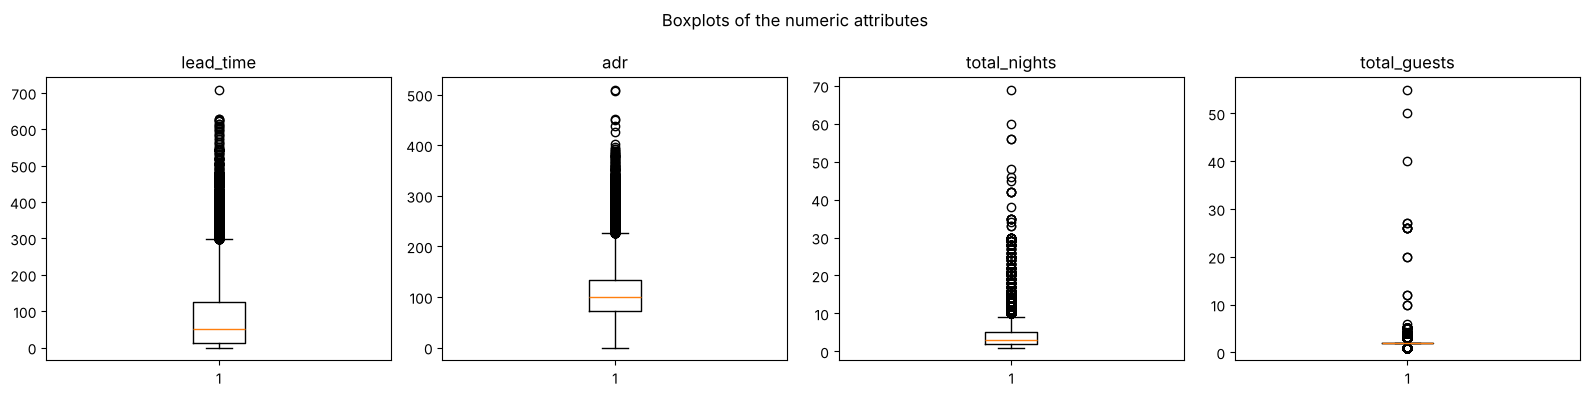

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ATTRIBUTES):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.suptitle("Boxplots of the numeric attributes")
plt.tight_layout()
plt.savefig(FIG_DIR / "out_01_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. IQR Method

A value is an outlier if it is below $Q1 - 1.5 \times IQR$ or above $Q3 + 1.5 \times IQR$, where $IQR = Q3 - Q1$.

In [4]:
iqr_rows = []
for col in ATTRIBUTES:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    iqr_rows.append({"attribute": col, "Q1": q1, "Q3": q3, "lower": lower, "upper": upper, "outliers": n_out})

iqr_table = pd.DataFrame(iqr_rows).set_index("attribute")
iqr_table.round(1)

,Q1,Q3,lower,upper,outliers
attribute,,,,,
lead_time,12.0,126.0,-159.0,297.0,2353
adr,72.9,134.4,-19.4,226.7,2511
total_nights,2.0,5.0,-2.5,9.5,2990
total_guests,2.0,2.0,2.0,2.0,29939


## 3. Z-score Method

$z = \frac{x - \text{mean}}{\text{std}}$ — a value is an outlier if $|z| > 3$.

In [5]:
z_rows = []
for col in ATTRIBUTES:
    z = (df[col] - df[col].mean()) / df[col].std()
    z_rows.append({"attribute": col,
                   "upper limit (z = 3)": df[col].mean() + 3 * df[col].std(),
                   "outliers": (z.abs() > 3).sum()})

z_table = pd.DataFrame(z_rows).set_index("attribute")
z_table.round(1)

,upper limit (z = 3),outliers
attribute,,
lead_time,338.5,1043
adr,261.1,876
total_nights,11.9,1552
total_guests,4.4,152


**Note:** for `total_guests`, Q1 = Q3 = 2, so IQR = 0 and the IQR method flags every booking that is not
2 guests (about 30,000). The IQR method is not suitable for this attribute; the Z-score method is used instead.

The Z-score is a **parametric** method: the mean and standard deviation assume that the data are roughly normal.
`lead_time` and `adr` are right-skewed (notebook 05), so the **nonparametric** IQR and histogram methods are used as a cross-check.

## 4. Histogram-Based Method (nonparametric)

The values are divided into intervals (bins). Bookings in bins with a low frequency are more likely to be outliers.
The **outlier score** is the inverse of the probability of the bin:

$$OutlierScore = \frac{1}{Probability\ of\ the\ bin}$$

A higher score means a more unusual observation. Here `adr` is divided into 10 equal-width bins.

In [6]:
adr_bins = pd.cut(df["adr"], bins=10)
counts = adr_bins.value_counts().sort_index()

hist_table = pd.DataFrame({"bookings": counts, "probability": counts / len(df)})
hist_table["outlier score"] = 1 / hist_table["probability"]
hist_table.round(4)

,bookings,probability,outlier score
adr,,,
"(-0.51, 51.0]",9385,0.1083,9.2314
"(51.0, 102.0]",36489,0.4212,2.3743
"(102.0, 153.0]",26684,0.3080,3.2468
"(153.0, 204.0]",9715,0.1121,8.9179
"(204.0, 255.0]",3302,0.0381,26.2377
"(255.0, 306.0]",842,0.0097,102.8943
"(306.0, 357.0]",180,0.0021,481.3167
"(357.0, 408.0]",34,0.0004,2548.1471
"(408.0, 459.0]",4,0.0000,21659.2500


In [7]:
rare_bins = hist_table[hist_table["probability"] < 0.01].index

print("Bins with probability < 1% (outlier score > 100): adr above", round(rare_bins[0].left, 1))
print("Bookings in these bins:", adr_bins.isin(rare_bins).sum())

Bins with probability < 1% (outlier score > 100): adr above 255.0
Bookings in these bins: 1062


Only the bins above about €255 have a probability below 1% (outlier score above 100): **1,062 bookings**.
They are a subset of the 2,511 bookings above the IQR fence (€226.7), so the histogram method points to the most extreme prices,
which are peak-season and large-room bookings (section 6.2).

## 5. Contextual Outliers

A price that is normal in July can be unusual in January. To find contextual outliers for `adr`:
- **Contextual attributes:** `hotel` and `arrival_date_month`
- **Behavioural attribute:** `adr`

The IQR rule is applied **inside each context** (each hotel and month) instead of on the whole dataset.

In [8]:
group = df.groupby(["hotel", "arrival_date_month"])["adr"]
q1_ctx = group.transform(lambda s: s.quantile(0.25))
q3_ctx = group.transform(lambda s: s.quantile(0.75))
iqr_ctx = q3_ctx - q1_ctx

low_ctx = df["adr"] < q1_ctx - 1.5 * iqr_ctx
high_ctx = df["adr"] > q3_ctx + 1.5 * iqr_ctx
contextual = low_ctx | high_ctx
global_out = (df["adr"] < iqr_table.loc["adr", "lower"]) | (df["adr"] > iqr_table.loc["adr", "upper"])

pd.Series({
    "Global outliers (IQR on all bookings)": global_out.sum(),
    "Contextual outliers (IQR per hotel and month)": contextual.sum(),
    "  flagged by both": (global_out & contextual).sum(),
    "  contextual only": (contextual & ~global_out).sum(),
    "  global only": (global_out & ~contextual).sum(),
})

Global outliers (IQR on all bookings)            2511
Contextual outliers (IQR per hotel and month)    3936
  flagged by both                                 871
  contextual only                                3065
  global only                                    1640
dtype: int64

In [9]:
print("Contextual outliers below the normal range:", low_ctx.sum(), "| of which adr = 0:", (low_ctx & (df["adr"] == 0)).sum())

only_context = df[contextual & ~global_out]
print("\nContextual-only outliers, reserved room type (top 4):")
print(only_context["reserved_room_type"].value_counts().head(4))
only_context[["hotel", "arrival_date_month", "adr", "reserved_room_type", "total_guests"]].head()

Contextual outliers below the normal range: 1074 | of which adr = 0: 883

Contextual-only outliers, reserved room type (top 4):
reserved_room_type
A    1031
F     561
D     489
G     404
Name: count, dtype: int64


,hotel,arrival_date_month,adr,reserved_room_type,total_guests
120,Resort Hotel,July,0.0,H,4
403,Resort Hotel,July,0.0,A,2
407,Resort Hotel,July,0.0,A,1
1127,Resort Hotel,August,8.0,D,2
1275,Resort Hotel,August,8.0,A,2


The two views flag different bookings:
- **1,640 global only:** high prices that are normal inside their own context (for example the Resort Hotel in summer). They are not contextual outliers.
- **3,065 contextual only:** prices that are unusual for their hotel and month although they are not extreme overall. 1,074 of them are below the normal range, mostly bookings with `adr = 0` (883) in months when the usual price is high. The rest are above the normal range for their month; the most common reserved room types are A, F, D and G.

A price of €0 is possible (for example a complimentary booking) and none of these bookings shows signs of a data-entry error, so they describe real prices and are **kept**.
The same price can be normal in one context and unusual in another, which is why the context matters.

## 6. Evaluating the Outliers

### 6.1 `total_guests`: problematic values

In [10]:
df[df["total_guests"] > 5][["adults", "children", "babies", "adr", "market_segment", "is_canceled"]]

,adults,children,babies,adr,market_segment,is_canceled
314,2,10,0,133.16,Offline TA/TO,1
1426,40,0,0,0.00,Direct,1
1474,26,0,0,0.00,Offline TA/TO,1
1528,50,0,0,0.00,Direct,1
1634,26,0,0,0.00,Offline TA/TO,1
1757,26,0,0,0.00,Offline TA/TO,1
1785,27,0,0,0.00,Direct,1
1828,27,0,0,0.00,Direct,1
1866,26,0,0,0.00,Offline TA/TO,1
2013,26,0,0,0.00,Offline TA/TO,1


The Z-score method flags 152 bookings with 5 or more guests. Bookings with 5 guests (135) are normal family
bookings, but the 17 bookings with **more than 5 guests** are **data-entry errors**: 20–55 adults in one room with a price of €0, or 9–10 babies with
1–2 adults. A hotel room does not hold these numbers of guests. They are **removed**.

### 6.2 `adr`: valid observations

In [11]:
upper_adr = iqr_table.loc["adr", "upper"]
high_adr = df[df["adr"] > upper_adr]

print("Bookings with adr above", round(upper_adr, 1), ":", len(high_adr))
print("\nArrival month (top 4):")
print(high_adr["arrival_date_month"].value_counts().head(4))
print("\nReserved room type (top 4):")
print(high_adr["reserved_room_type"].value_counts().head(4))

Bookings with adr above 226.7 : 2511

Arrival month (top 4):
arrival_date_month
August    1397
July       574
June       153
May        119
Name: count, dtype: int64

Reserved room type (top 4):
reserved_room_type
G    587
F    476
D    401
E    370
Name: count, dtype: int64


High prices are mostly in summer months and in larger room types, so they are **valid observations**
(peak-season and family rooms), not errors. They are **kept**.

### 6.3 `lead_time` and `total_nights`: valid observations

In [12]:
print(df.nlargest(5, "lead_time")[["lead_time", "market_segment", "customer_type", "is_canceled"]], "\n")
print(df.nlargest(5, "total_nights")[["total_nights", "market_segment", "customer_type", "adr"]])

       lead_time market_segment customer_type  is_canceled
3309         709         Direct     Transient            0
47345        629         Groups     Transient            1
47350        629         Groups     Transient            1
44316        626         Groups     Transient            1
47206        622         Groups     Transient            1 

       total_nights market_segment    customer_type     adr
10743            69         Direct        Transient  110.00
10742            60         Direct        Transient  110.50
7319             56  Offline TA/TO        Transient   25.50
27988            56      Online TA        Transient   28.79
41467            48      Online TA  Transient-Party    0.00


Bookings made up to two years in advance and stays of several weeks are possible in real hotels.
They describe real customer behaviour (for example, early bookings are canceled more often), so they are **kept**.
Decision trees are not affected by extreme values, because they split on thresholds.

## 7. Handling the Outliers

| Attribute | Method | Outliers | Evaluation | Action |
|---|---|---|---|---|
| total_guests | Z-score | 152 (≥ 5 guests) | 17 bookings with > 5 guests are data-entry errors | **remove the 17** |
| adr | IQR / Z-score | 2,511 / 876 | peak season, large rooms | keep |
| lead_time | IQR / Z-score | 2,353 / 1,043 | real early bookings | keep |
| total_nights | IQR / Z-score | 2,990 / 1,552 | real long stays | keep |

The histogram and contextual methods examine the same attribute (`adr`) and show real prices (peak season, specific rooms, a price of €0), so the decision does not change:
only the **17 bookings with more than 5 guests** are removed.

In [13]:
before = len(df)
df_final = df[df["total_guests"] <= 5].copy()
print(f"{before:,} → {len(df_final):,} rows (removed {before - len(df_final)})")

df_final.to_csv("../data/processed/hotel_bookings_final.csv", index=False)
print("Saved: ../data/processed/hotel_bookings_final.csv")

86,637 → 86,620 rows (removed 17)


Saved: ../data/processed/hotel_bookings_final.csv
